必要なライブラリとモジュールのインストール

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import tkinter as tk
from tkinter import filedialog
import warnings

# 警告を非表示
warnings.simplefilter(action='ignore', category=FutureWarning)

# --- フォント設定 ---
font_file_path = r"C:\Users\0uh2j\OneDrive\Desktop\IPAexfont00401\ipaexg.ttf"
if os.path.exists(font_file_path):
    try:
        fm.fontManager.addfont(font_file_path)
        font_prop = fm.FontProperties(fname=font_file_path)
        plt.rcParams['font.family'] = font_prop.get_name()
        print(f"フォント適用: {font_prop.get_name()}")
    except Exception as e:
        print(f"フォント設定エラー: {e}")
else:
    print("デフォルトフォントを使用します。")

フォント適用: IPAexGothic


学習データファイル(CSVファイル)選択

In [2]:
root = tk.Tk()
root.withdraw()
print("分析するCSVファイルを選択してください...")
csv_file_path = filedialog.askopenfilename(
    title="CSVファイルを選択してください",
    filetypes=[("CSVファイル", "*.csv"), ("すべてのファイル", "*.*")]
)
data_loaded = False

分析するCSVファイルを選択してください...


データ読み込みと前処理

In [3]:
if csv_file_path:
    try:
        df = pd.read_csv(csv_file_path)
        
        # 列名の定義
        col_temp = '流動中樹脂温度T3(℃)'
        col_pres = '流動中樹脂圧力P23(Pa)'
        col_sr = 'せん断速度γ23(1/s)'
        col_visc = '樹脂粘度η23(Pa・s)'
        
        required_columns = [col_temp, col_pres, col_sr, col_visc]
        if not all(col in df.columns for col in required_columns):
            raise ValueError(f"必要な列が不足しています: {required_columns}")

        # 前処理 (単位変換と対数変換)
        df['流動中樹脂温度T3(K)'] = df[col_temp] + 273.15
        
        # ログ計算用の一時変数
        # ※インデックスを保持するためにdfに新しい列として追加する方法もありますが、
        # ここではシンプルに配列として処理し、インデックス管理は後で行います。
        log_T = np.log(df['流動中樹脂温度T3(K)'].values)
        log_P = np.log(df[col_pres].values)
        log_SR = np.log(df[col_sr].values)
        log_VISC = np.log(df[col_visc].values)
        
        # 入力データ X と目的変数 y の作成
        X_raw = np.stack([log_T, log_P, log_SR], axis=1)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_raw)
        
        y_mean = log_VISC.mean()
        y_centered = log_VISC - y_mean
        
        data_loaded = True
        print(f"データ読み込み完了: 全 {len(X_scaled)} 件")
        
    except Exception as e:
        print(f"エラーが発生しました: {e}")

データ読み込み完了: 全 1076 件


学習データとテストデータの分割設定(公差検証法)

In [13]:
# セル4: 【重要】学習データとテストデータの分割設定 (範囲指定対応版)
if data_loaded:
    print("--- データの分割設定 ---")

    # ==========================================================
    # ▼▼▼ 設定エリア：ここで分割方法を決定してください ▼▼▼
    
    # モード選択: "random" または "condition"
    split_mode = "condition" 
    
    # 【設定A】 "random" の場合の設定
    test_ratio = 0.2  # テストデータの割合 (0.2 = 20%)
    
    # 【設定B】 "condition" の場合の設定 (範囲指定)
    # 指定した「下限値」から「上限値」の範囲内にあるデータをテスト用(検証用)にします。
    # それ以外のデータ(範囲外)を使って学習を行います。
    # 例: 温度が 200℃ 〜 210℃ のデータをテスト用にくり抜く場合
    
    target_column = 'せん断速度γ23(1/s)' # 条件を判断する列名
    
    test_range_min = 6000   # テストデータにする範囲の下限
    test_range_max = 7000   # テストデータにする範囲の上限
    
    # ▲▲▲ 設定エリア終了 ▲▲▲
    # ==========================================================

    indices = np.arange(len(X_scaled))

    if split_mode == "random":
        # ランダム分割
        X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
            X_scaled, y_centered, indices, test_size=test_ratio, random_state=42
        )
        print(f"【ランダム分割モード】 全体の {test_ratio*100}% をテストデータにしました。")

    elif split_mode == "condition":
        # 条件指定分割 (範囲指定)
        # ターゲット列の値を取得
        target_values = df[target_column].values
        
        # 範囲内 (min <= x <= max) をテストデータとするマスクを作成
        test_mask = (target_values >= test_range_min) & (target_values <= test_range_max)
        
        condition_str = f"{test_range_min} <= {target_column} <= {test_range_max}"
            
        idx_test = indices[test_mask]
        idx_train = indices[~test_mask] # maskの反転(Not) = 学習データ
        
        # エラーチェック
        if len(idx_test) == 0:
            print(f"【警告】指定された範囲({condition_str})にデータが1件もありません。")
            print("設定を見直すか、範囲を広げてください。")
        elif len(idx_train) == 0:
            print(f"【警告】全てのデータがテスト範囲に含まれてしまいました。学習できるデータがありません。")
            print("範囲を狭めてください。")
        else:
            X_train = X_scaled[idx_train]
            y_train = y_centered[idx_train]
            X_test = X_scaled[idx_test]
            y_test = y_centered[idx_test]
            print(f"【条件指定モード(範囲)】")
            print(f"条件: 「{condition_str}」 のデータをテスト(検証)用にしました。")
            print(f"それ以外のデータを学習に使用します。")

    # データ数の表示
    if 'X_train' in locals() and 'X_test' in locals():
        print(f"  - 学習用データ数: {len(X_train)} 件")
        print(f"  - テスト用データ数: {len(X_test)} 件")
        # 学習実行フラグ
        ready_to_train = len(X_train) > 0 and len(X_test) > 0
    else:
        ready_to_train = False

--- データの分割設定 ---
【条件指定モード(範囲)】
条件: 「6000 <= せん断速度γ23(1/s) <= 7000」 のデータをテスト(検証)用にしました。
それ以外のデータを学習に使用します。
  - 学習用データ数: 1005 件
  - テスト用データ数: 71 件


機械学習モデル構築と学習

In [14]:
from scipy.optimize import minimize

# 進捗表示用コールバック
def custom_optimizer(obj_func, initial_theta, bounds):
    print(f"  > 最適化計算中", end="")
    def callback(xk):
        print(".", end="", flush=True)
    res = minimize(obj_func, initial_theta, bounds=bounds, method="L-BFGS-B", jac=True, callback=callback)
    print(" 完了")
    return res.x, res.fun

if data_loaded and ready_to_train:
    print("\n--- 学習プロセス開始 (scikit-learn) ---")
    
    # 計算負荷軽減のため、学習データが2000件を超える場合はダウンサンプリング
    N_MAX_TRAIN = 2000
    if len(X_train) > N_MAX_TRAIN:
        print(f"※学習データ({len(X_train)})が多いため、ランダムに{N_MAX_TRAIN}件を使用してモデル構築します。")
        fit_indices = np.random.choice(len(X_train), N_MAX_TRAIN, replace=False)
        X_train_fit = X_train[fit_indices]
        y_train_fit = y_train[fit_indices]
    else:
        X_train_fit = X_train
        y_train_fit = y_train

    # ARDカーネル定義
    kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=[1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)) + \
             WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
    
    gp_model = GaussianProcessRegressor(
        kernel=kernel, 
        n_restarts_optimizer=5, # 進捗が見えるので回数は適度でOK
        optimizer=custom_optimizer,
        random_state=42
    )
    
    # 学習実行
    gp_model.fit(X_train_fit, y_train_fit)
    
    print("--- 学習完了 ---")
    print(f"獲得したカーネル: {gp_model.kernel_}")
    learning_completed = True


--- 学習プロセス開始 (scikit-learn) ---
  > 最適化計算中....................... 完了
  > 最適化計算中..................... 完了
  > 最適化計算中...................... 完了
  > 最適化計算中........................... 完了
  > 最適化計算中............. 完了
  > 最適化計算中................ 完了
--- 学習完了 ---
獲得したカーネル: 0.684**2 * RBF(length_scale=[0.549, 0.305, 1.33]) + WhiteKernel(noise_level=8.09e-05)


結果の検証（パリティプロット ＋ 依存性グラフ）


--- 検証結果の可視化 (縦並び・個別カラーバー版) ---


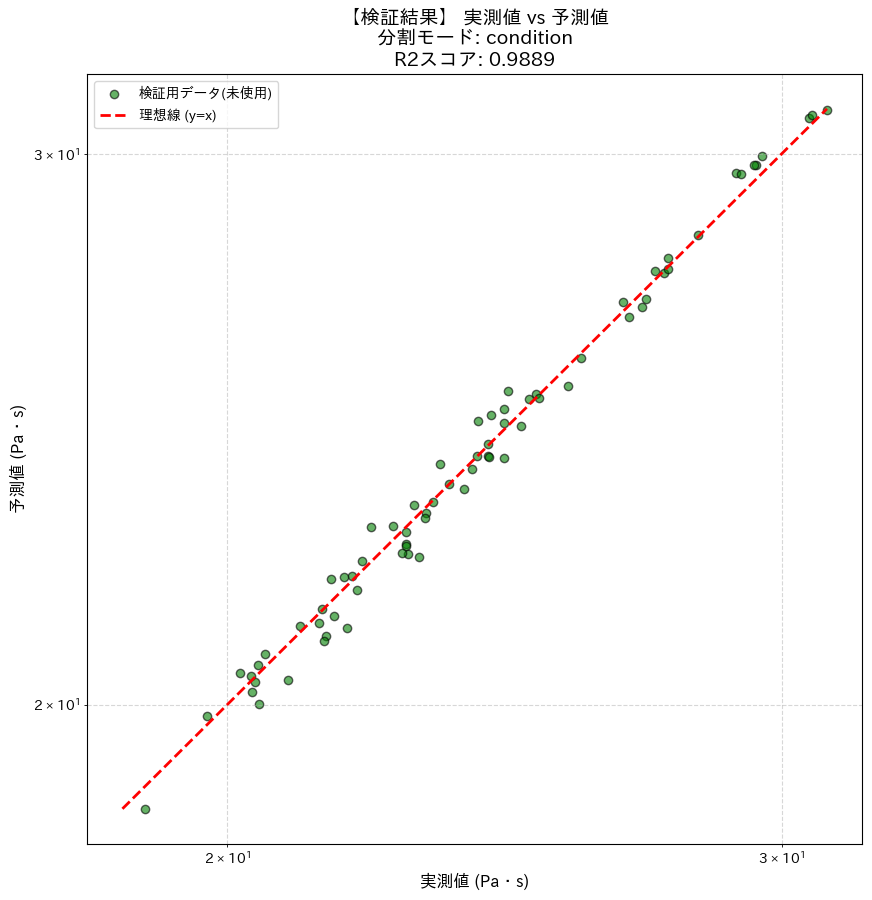

決定係数(R2): 0.9889 (1に近いほど高精度)
>> 判定: 【合格】 未知のデータに対しても高い予測精度が出ています。

--- 変数ごとの依存性プロット ---


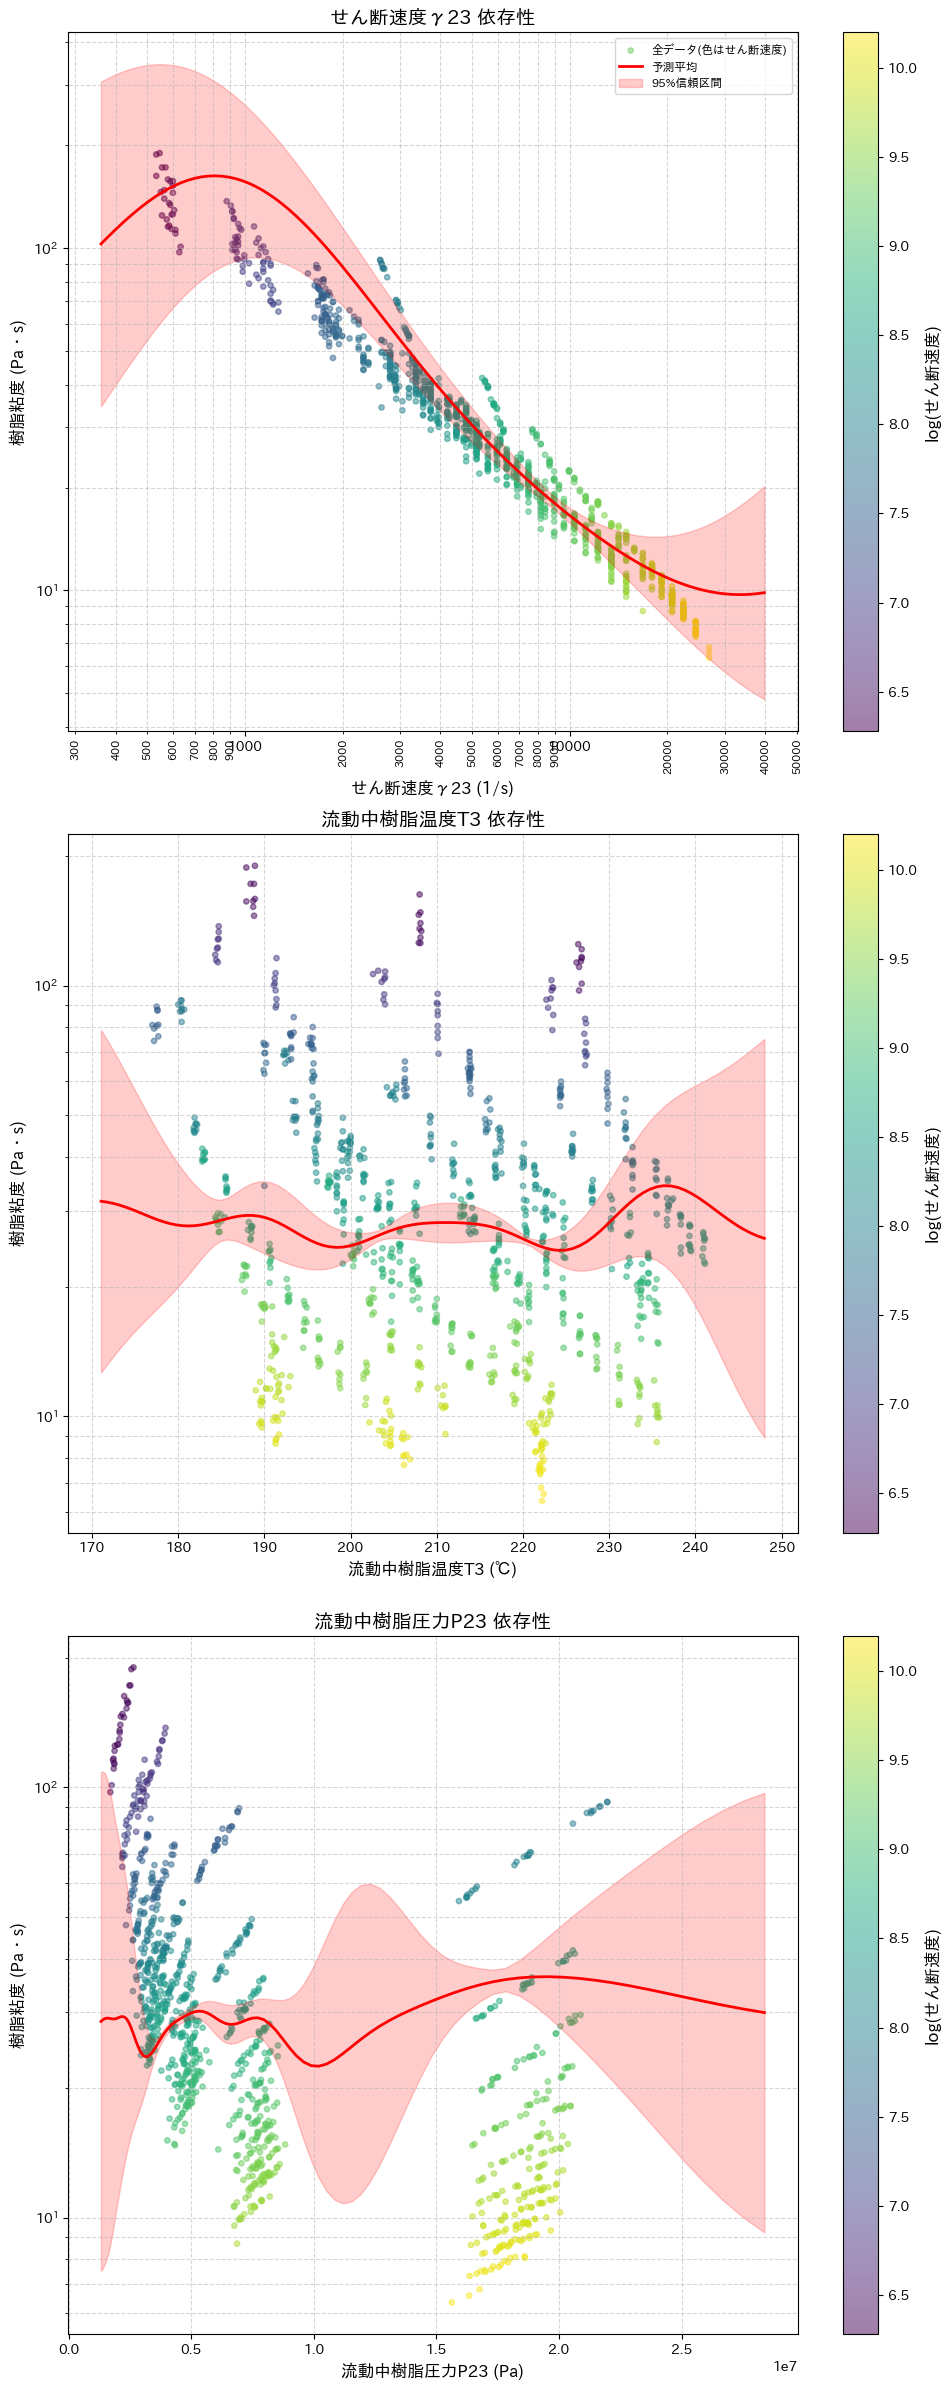

In [ ]:
import matplotlib.ticker as ticker # 目盛り調整用ライブラリ

if learning_completed:
    print("\n--- 検証結果の可視化 (縦並び・個別カラーバー版) ---")
    
    # === 1. パリティプロット (精度検証) ===
    # テストデータに対する予測
    y_pred_test_centered, y_std_test = gp_model.predict(X_test, return_std=True)
    
    # 実数値に戻す
    y_test_real = np.exp(y_test + y_mean)
    y_pred_real = np.exp(y_pred_test_centered + y_mean)
    
    # 精度スコア
    r2 = r2_score(y_test_real, y_pred_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    
    # パリティプロットは見やすさのため正方形に近いサイズにします
    plt.figure(figsize=(10, 10))
    plt.scatter(y_test_real, y_pred_real, c='green', alpha=0.6, edgecolors='k', label='検証用データ(未使用)')
    
    # 理想線
    min_val = min(y_test_real.min(), y_pred_real.min())
    max_val = max(y_test_real.max(), y_pred_real.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='理想線 (y=x)')
    
    plt.xscale('log'); plt.yscale('log')
    plt.title(f"【検証結果】 実測値 vs 予測値\n分割モード: {split_mode}\nR2スコア: {r2:.4f}", fontsize=14)
    plt.xlabel("実測値 (Pa・s)", fontsize=12)
    plt.ylabel("予測値 (Pa・s)", fontsize=12)
    plt.legend(); plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.show()
    
    print(f"決定係数(R2): {r2:.4f} (1に近いほど高精度)")
    if r2 > 0.8:
        print(">> 判定: 【合格】 未知のデータに対しても高い予測精度が出ています。")
    else:
        print(">> 判定: 【注意】 テストデータの予測精度が低めです。過学習またはデータの範囲外予測の可能性があります。")


    # === 2. 依存性プロット (傾向確認・縦並び) ===
    print("\n--- 変数ごとの依存性プロット ---")
    
    # ★変更点: グラフを縦に3つ並べるため、nrows=3, ncols=1 に設定
    # figsize=(幅, 高さ) を縦長に調整 (例: 幅10インチ, 高さ24インチ)
    fig, axes = plt.subplots(3, 1, figsize=(20, 10))
    
    # 表示設定
    plot_configs = [
        {'name': 'せん断速度γ23',    'unit': '(1/s)', 'data_idx': 2},
        {'name': '流動中樹脂温度T3',  'unit': '(℃)',   'data_idx': 0},
        {'name': '流動中樹脂圧力P23',  'unit': '(Pa)',  'data_idx': 1}
    ]
    
    n_grid = 100
    
    # --- 色分け設定 (せん断速度に基づく) ---
    shear_rates_log_all = X_raw[:, 2] 
    norm = plt.Normalize(vmin=shear_rates_log_all.min(), vmax=shear_rates_log_all.max())
    cmap = 'viridis' 
    
    for i, config in enumerate(plot_configs):
        ax = axes[i]
        d_idx = config['data_idx']
        var_name = config['name']
        
        # 予測用グリッド作成
        x_min, x_max = X_scaled[:, d_idx].min(), X_scaled[:, d_idx].max()
        padding = (x_max - x_min) * 0.1
        x_grid = np.linspace(x_min - padding, x_max + padding, n_grid)
        
        X_new_scaled = np.zeros((n_grid, 3))
        X_new_scaled[:, d_idx] = x_grid
        
        # 予測
        y_pred, y_std = gp_model.predict(X_new_scaled, return_std=True)
        
        # 逆変換
        visc_mean = np.exp(y_pred + y_mean)
        visc_lower = np.exp(y_pred - 1.96*y_std + y_mean)
        visc_upper = np.exp(y_pred + 1.96*y_std + y_mean)
        
        x_grid_real = np.exp(x_grid * scaler.scale_[d_idx] + scaler.mean_[d_idx])
        if d_idx == 0: x_grid_real -= 273.15
            
        # 学習データのプロット 
        idx_sample = np.random.choice(len(X_raw), size=min(2000, len(X_raw)), replace=False)
        x_raw_sample = np.exp(X_raw[idx_sample, d_idx])
        y_raw_sample = np.exp(y_centered[idx_sample] + y_mean)
        c_sample = X_raw[idx_sample, 2] # logせん断速度
        
        if d_idx == 0: x_raw_sample -= 273.15
            
        # 散布図プロット
        sc = ax.scatter(x_raw_sample, y_raw_sample, c=c_sample, cmap=cmap, norm=norm,
                        alpha=0.5, s=15, label='全データ(色はせん断速度)')
        
        ax.plot(x_grid_real, visc_mean, color='red', linewidth=2, label='予測平均')
        ax.fill_between(x_grid_real, visc_lower, visc_upper, color='red', alpha=0.2, label='95%信頼区間')
        
        ax.set_title(f"{var_name} 依存性", fontsize=14)
        ax.set_xlabel(f"{var_name} {config['unit']}", fontsize=12)
        ax.set_ylabel("樹脂粘度 (Pa・s)", fontsize=12)
        ax.set_yscale('log')
        
        # せん断速度のグラフの場合の設定（対数軸の目盛り詳細表示）
        if d_idx == 2: 
            ax.set_xscale('log')
            # 細かい目盛り(2000, 3000...)を表示
            ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(0.1, 1.0, 0.1), numticks=10))
            ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
            ax.xaxis.set_minor_formatter(ticker.ScalarFormatter())
            ax.tick_params(axis='x', which='minor', rotation=90, labelsize=8)
            ax.tick_params(axis='x', which='major', rotation=0, labelsize=10)

        ax.grid(True, which="both", linestyle='--', alpha=0.5)
        if i == 0: ax.legend(loc='upper right', fontsize='small')
        
        # ★変更点: 各グラフの横にカラーバーを追加
        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label('log(せん断速度)', fontsize=12)

    plt.tight_layout()
    plt.show()